# WEG · B3 equity research

**Victor Pimenta · avaliação em 06/11/2026 · base TTM 30/09/2026.**

Este notebook reproduz o DCF, os 10.000 cenários e os quatro gráficos sem rede.
A cotação é um snapshot com horário e fonte, não uma promessa de preço em tempo real.
[Pitch](../docs/pitch.md) · [Metodologia](../docs/methodology.md) · [Setor](../docs/industry-deep-dive.md).
As distribuições são hipóteses do autor, não probabilidades calibradas de retorno.

In [1]:
# Colab: installs the package from this public repository; no token or upload needed.
import importlib.util
import subprocess
import sys

if "google.colab" in sys.modules and importlib.util.find_spec("dcf_valuation") is None:
    repository = "git+https://github.com/VictorPimentaDev/dcf-valuation-model.git"
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", repository], check=True)


In [2]:
from pathlib import Path

import numpy_financial as npf
import pandas as pd
from IPython.display import Image, display

from dcf_valuation.charts import save_charts
from dcf_valuation.market import get_quote
from dcf_valuation.model import calculate, load_assumptions, load_data
from dcf_valuation.monte_carlo import SimulationConfig, simulate, tornado
from dcf_valuation.workbook import build_workbook

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
output = root / "outputs" / "notebook"
output.mkdir(parents=True, exist_ok=True)
data = load_data()
a = load_assumptions(data)
quote = get_quote()  # Offline. Para coleta explícita, get_quote(live=True).
print("Avaliação:", data["valuation_date"], "| Fundamentos:", data["financial_period_end"])
display(pd.Series(quote, name="Cotação observada"))

Avaliação: 2026-11-06 | Fundamentos: 2026-09-30


ticker                                                 WEGE3.SA
currency                                                    BRL
price                                                     48.23
timestamp                             2026-11-06T17:50:34-03:00
fetched_at                     2026-11-06T21:05:36.399375+00:00
source_url            https://finance.yahoo.com/quote/WEGE3.SA/
provider      Yahoo Finance via yfinance; regularMarketPrice...
mode                                                   snapshot
Name: Cotação observada, dtype: object

## Histórico e base comparável

DFP FY2025 + ITR 9M2026 − comparativo 9M2025 produz TTM até setembro de 2026.
EBITDA = EBIT + D&A da DFC. Não há anualização de um trimestre nem EBITDA ajustado.
Os ZIPs oficiais e hashes estão no fixture; `cvm_weg.csv` permite auditar as contas.
Todos os valores abaixo são R$ milhões.

In [3]:
history = pd.DataFrame(data["historical"]).set_index("period")
history["ebit"] = history.ebitda - history.da
history["ebit_margin"] = history.ebit / history.revenue
display(history.drop(columns="year").round(4))
display(pd.DataFrame(data["sources"])[["id", "url", "scope"]])

,revenue,ebitda,da,ebit,ebit_margin
period,,,,,
FY2024,37986.941,8503.013,812.485,7690.528,0.2025
FY2025,40804.110,9000.037,1001.296,7998.741,0.1960
TTM Sep2026,40719.467,8952.604,1068.117,7884.487,0.1936


,id,url,scope
0,DFP24,https://api.mziq.com/mzfilemanager/v2/d/50c1bd...,Descrição dos negócios (pp. 3–4). Referência d...
1,CVMDFP2025,https://dados.cvm.gov.br/dados/CIA_ABERTA/DOC/...,FY2024 e FY2025 (exercícios encerrados em 31/12)
2,CVMITR2026,https://dados.cvm.gov.br/dados/CIA_ABERTA/DOC/...,9M2025 e 9M2026; saldos e composição do capita...
3,AUTHOR,,Próximos 5 períodos de 12 meses desde 06/11/2026


## DCF determinístico

Crescimento de 12% a 8%, margem EBIT 20%, capex 4,5%, D&A 2,5%, NWC 20%,
imposto 34%, WACC 14,652% e g 4% são ilustrativos. Os fluxos são cinco períodos
completos de 12 meses após a avaliação. NCI contábil é proxy de outros direitos;
a ponte de setembro não tem roll-forward até novembro.

In [4]:
base = calculate(a, data)
flows = pd.DataFrame(base["projections"])
display(flows.round(3))
terminal = flows.fcff.iloc[-1] * (1 + a.terminal_growth) / (a.discount_rate - a.terminal_growth)
check_ev = npf.npv(a.discount_rate, [0, *flows.fcff]) + terminal / (1 + a.discount_rate) ** 5
assert abs(check_ev - base["enterprise_value"]) < 1e-8
print(f"DCF base: R$ {base['price_per_share']:.2f}/ação")
print(f"Spread vs cotação observada: {base['price_per_share'] / quote['price'] - 1:.1%}")

,year,period_end,revenue,ebit,da,capex,nwc,delta_nwc,fcff
0,2027,2027-11-06,45605.803,9121.161,1140.145,2052.261,9121.161,977.267,4130.583
1,2028,2028-11-06,50622.441,10124.488,1265.561,2278.010,10124.488,1003.328,4666.386
2,2029,2029-11-06,55684.686,11136.937,1392.117,2505.811,11136.937,1012.449,5224.236
3,2030,2030-11-06,60696.307,12139.261,1517.408,2731.334,12139.261,1002.324,5795.662
4,2031,2031-11-06,65552.012,13110.402,1638.800,2949.841,13110.402,971.141,6370.684


DCF base: R$ 11.67/ação
Spread vs cotação observada: -75.8%


## Monte Carlo nos quatro drivers

Triangulares independentes, moda no cenário base, amplitudes ±5 pp crescimento,
±4 pp margem, ±2,5 pp WACC, ±1,5 pp g. Crescimento e margem usam um choque
persistente nos cinco anos. Suporte inteiro deve satisfazer WACC > g.
O percentual acima da cotação é uma frequência **do modelo**, não probabilidade
de ganho na bolsa. Intervalos não incluem todo risco econômico.

In [5]:
config = SimulationConfig(samples=10_000, seed=42)
simulation = simulate(a, config, data)
assert (simulation.samples.wacc > simulation.samples.terminal_growth).all()
assert len(simulation.samples) == config.samples
display(pd.Series(simulation.summary, name="Fair value BRL/share").round(3))
print("Fração de cenários acima da cotação:",
      f"{(simulation.samples.price_per_share > quote['price']).mean():.2%}")
display(tornado(a, config, data).round(3))

mean    11.825
p05      8.952
p10      9.455
p25     10.405
p50     11.650
p75     13.040
p90     14.445
p95     15.255
Name: Fair value BRL/share, dtype: float64

Fração de cenários acima da cotação: 0.00%


,p10_input,p90_input
driver,,
growth,11.005,12.358
margin,9.909,13.432
wacc,13.473,10.285
terminal,11.075,12.367


## Figuras e Excel

O fan chart é de receita; o tornado muda um driver por vez (P10/P90).
As barras P5–P95 no gráfico comparativo são percentis condicionais do fair value,
não uma previsão de preço futuro. A aba MonteCarlo do Excel guarda um snapshot:
é preciso regerar após mudar premissas, seed ou dados.

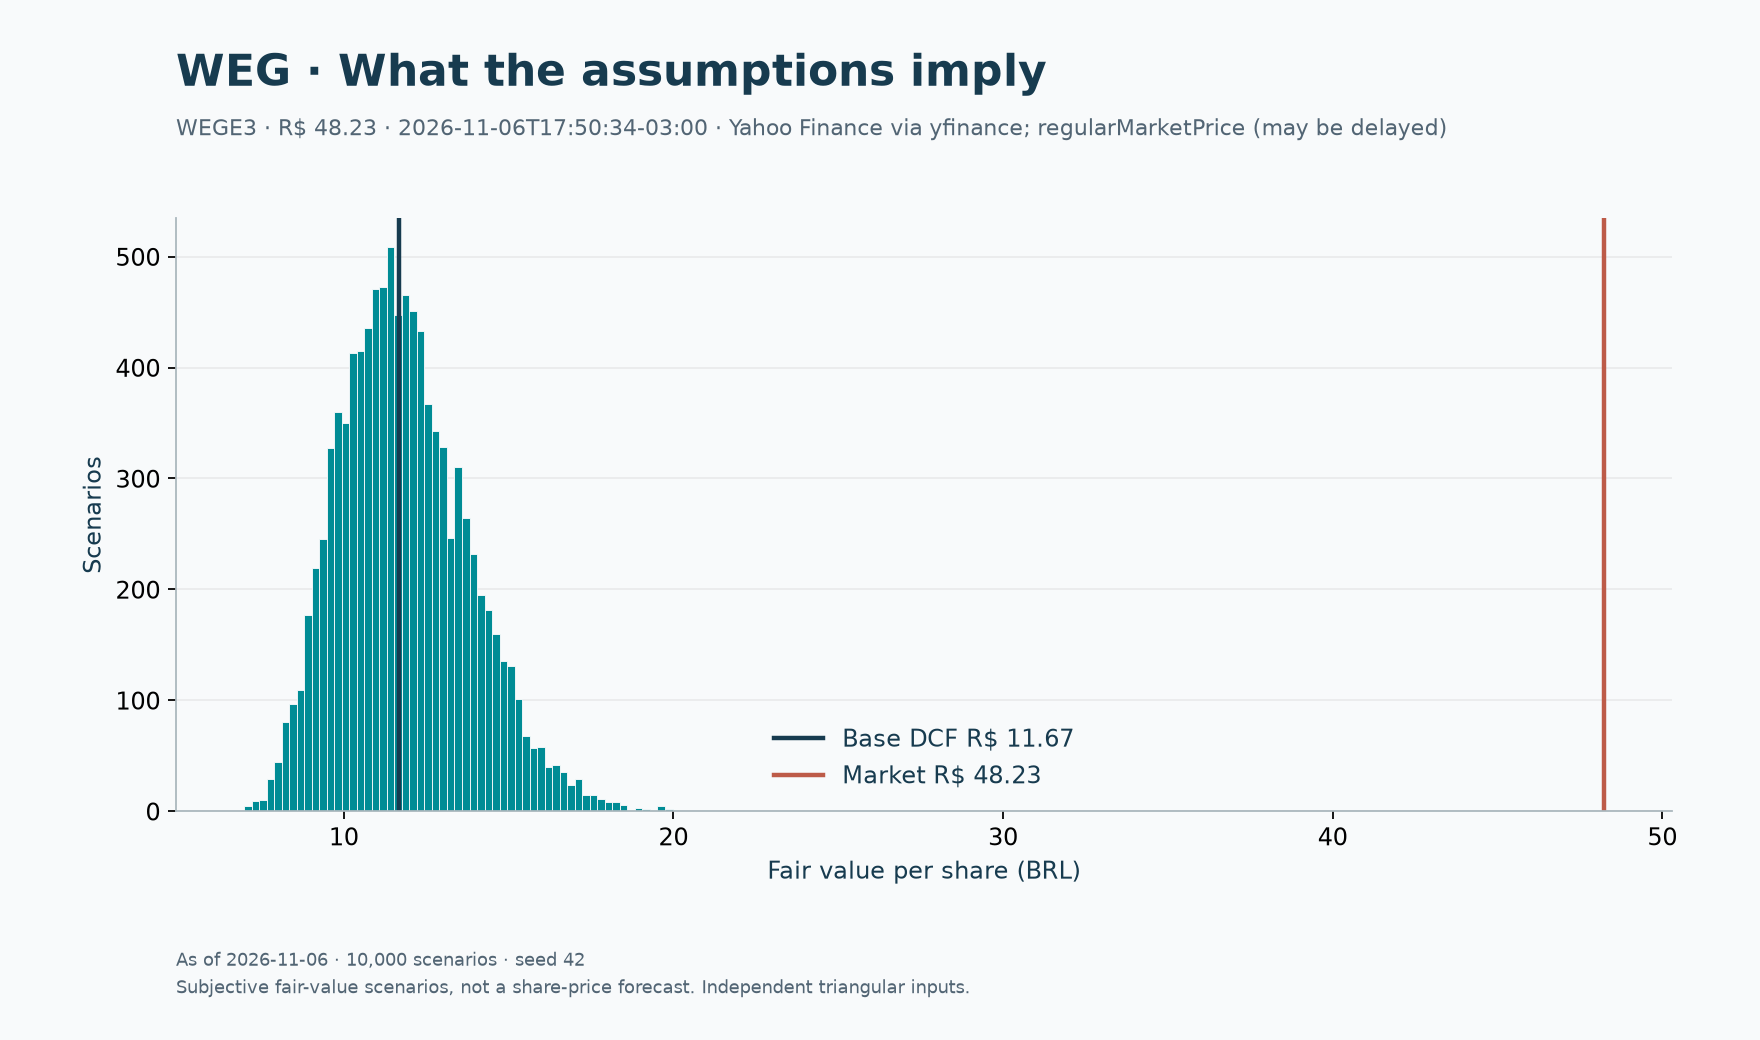

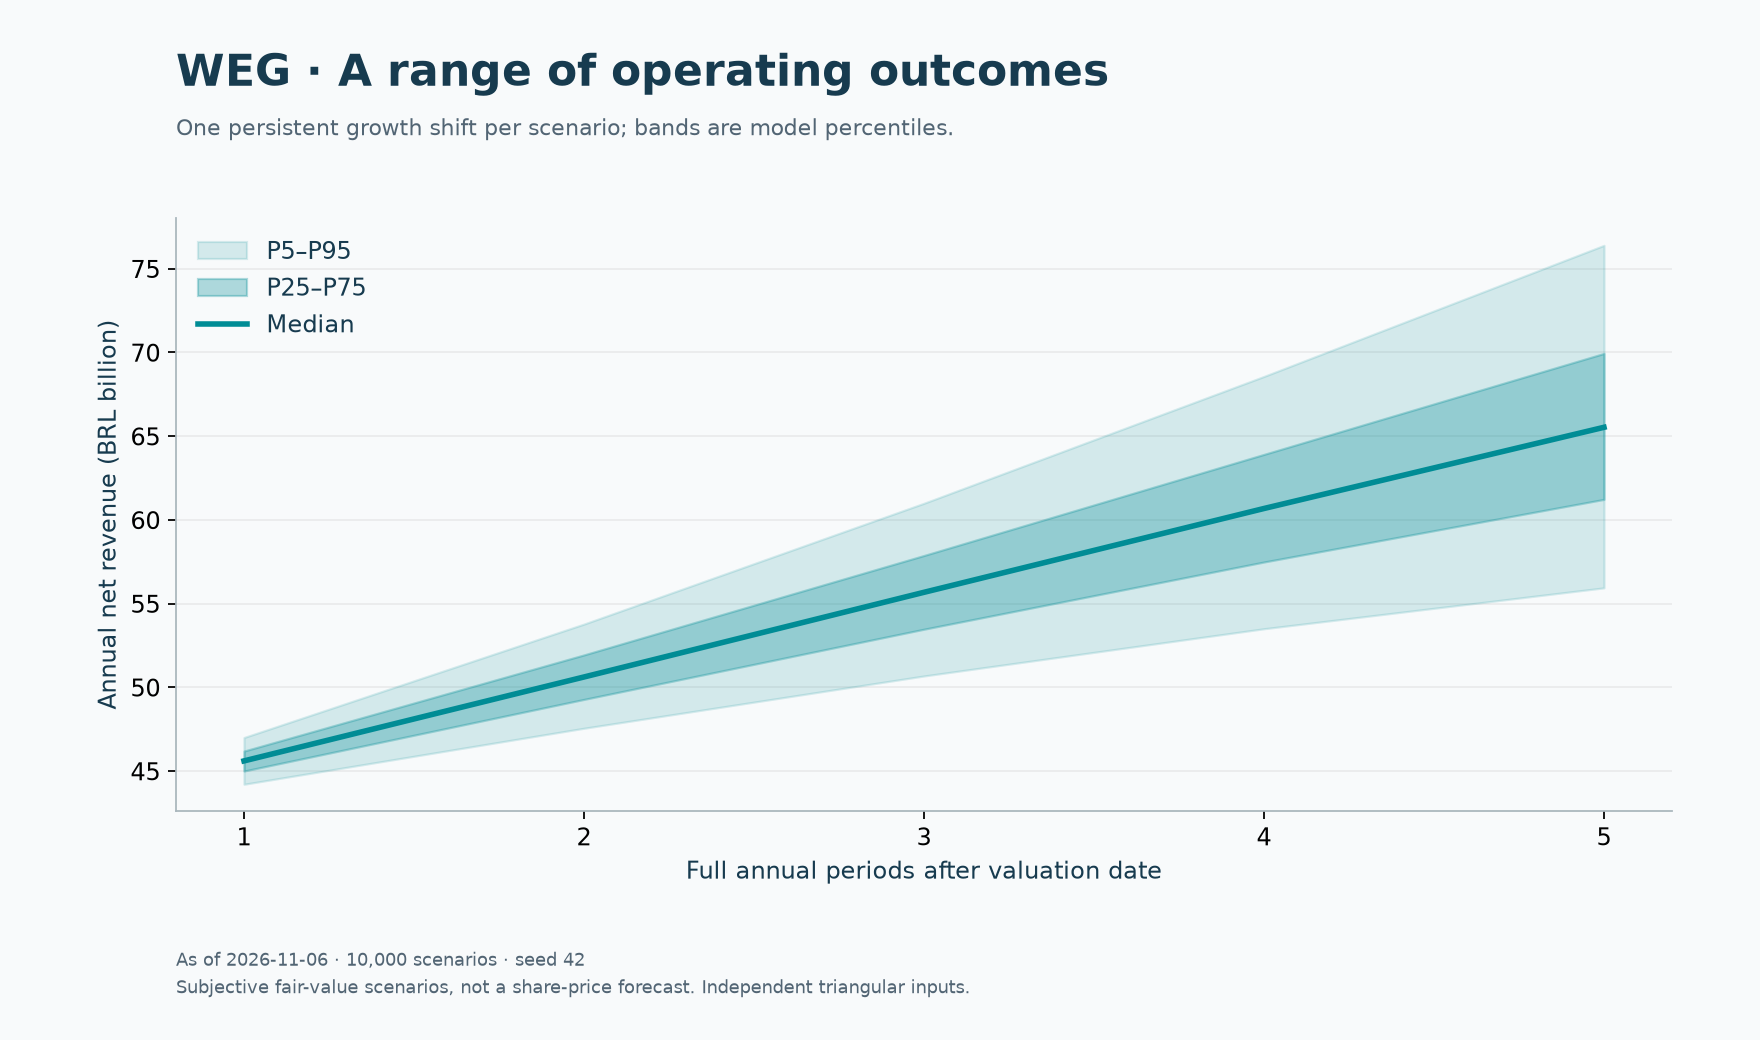

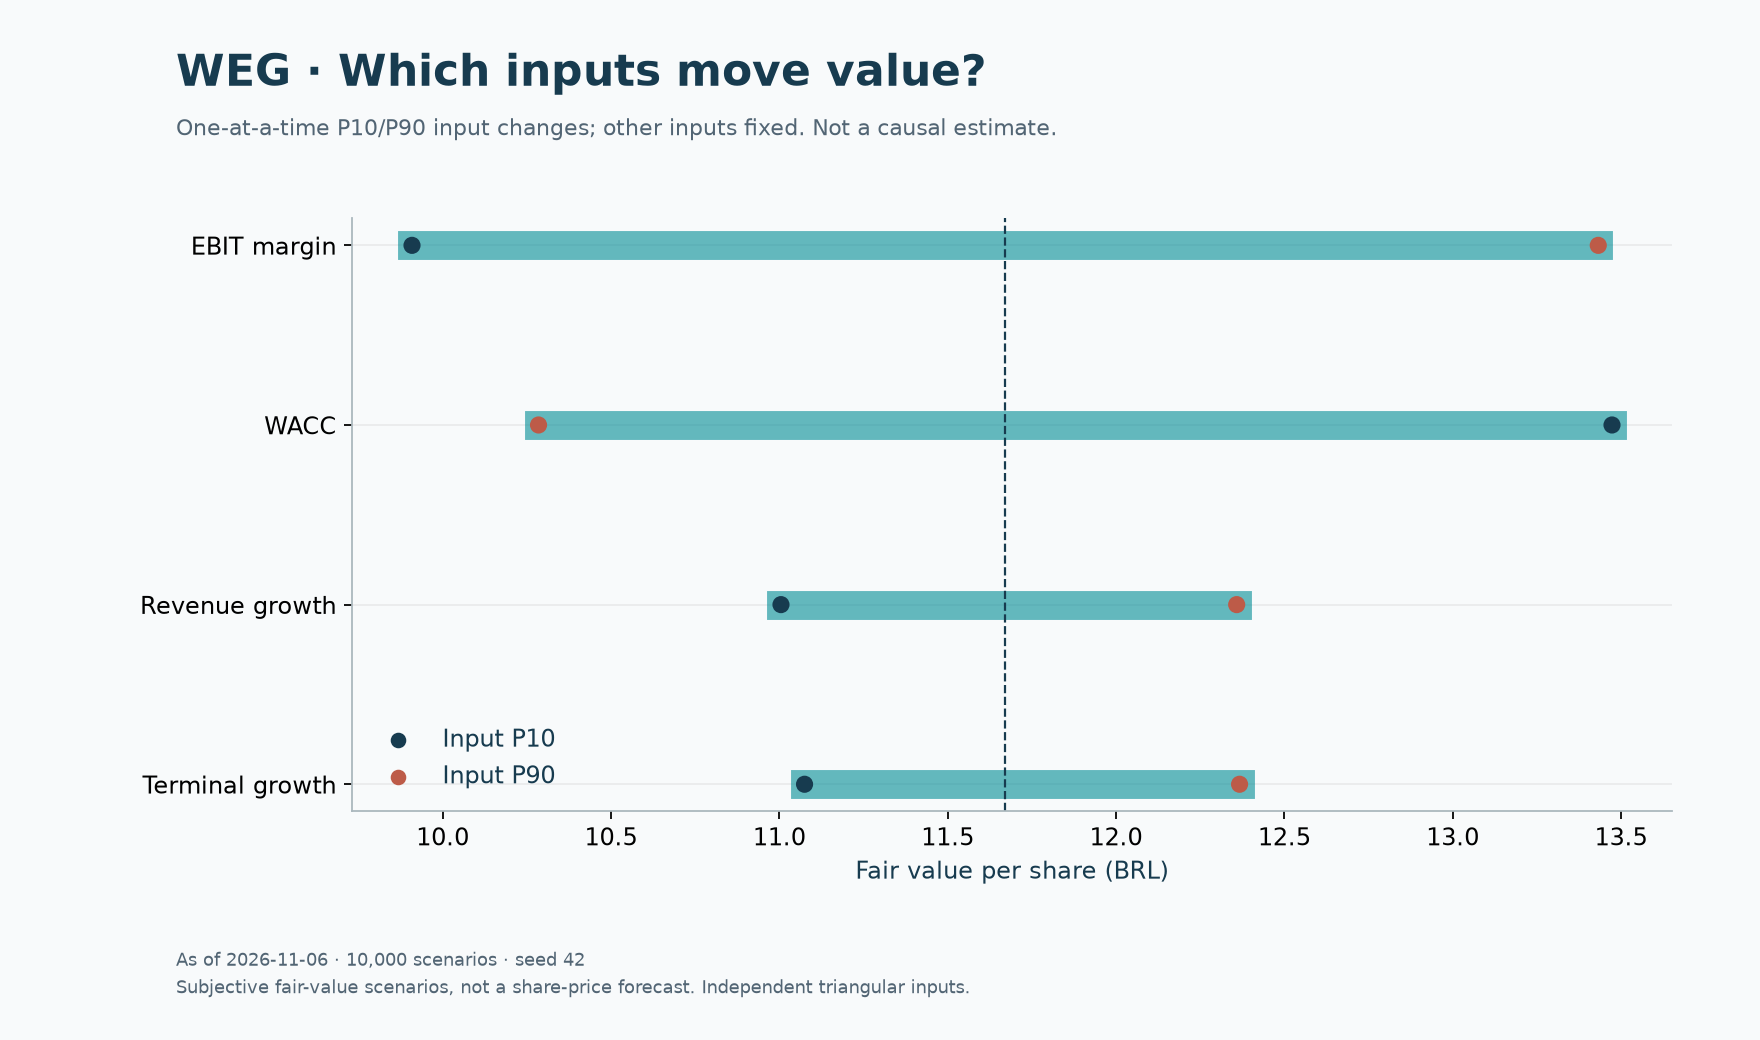

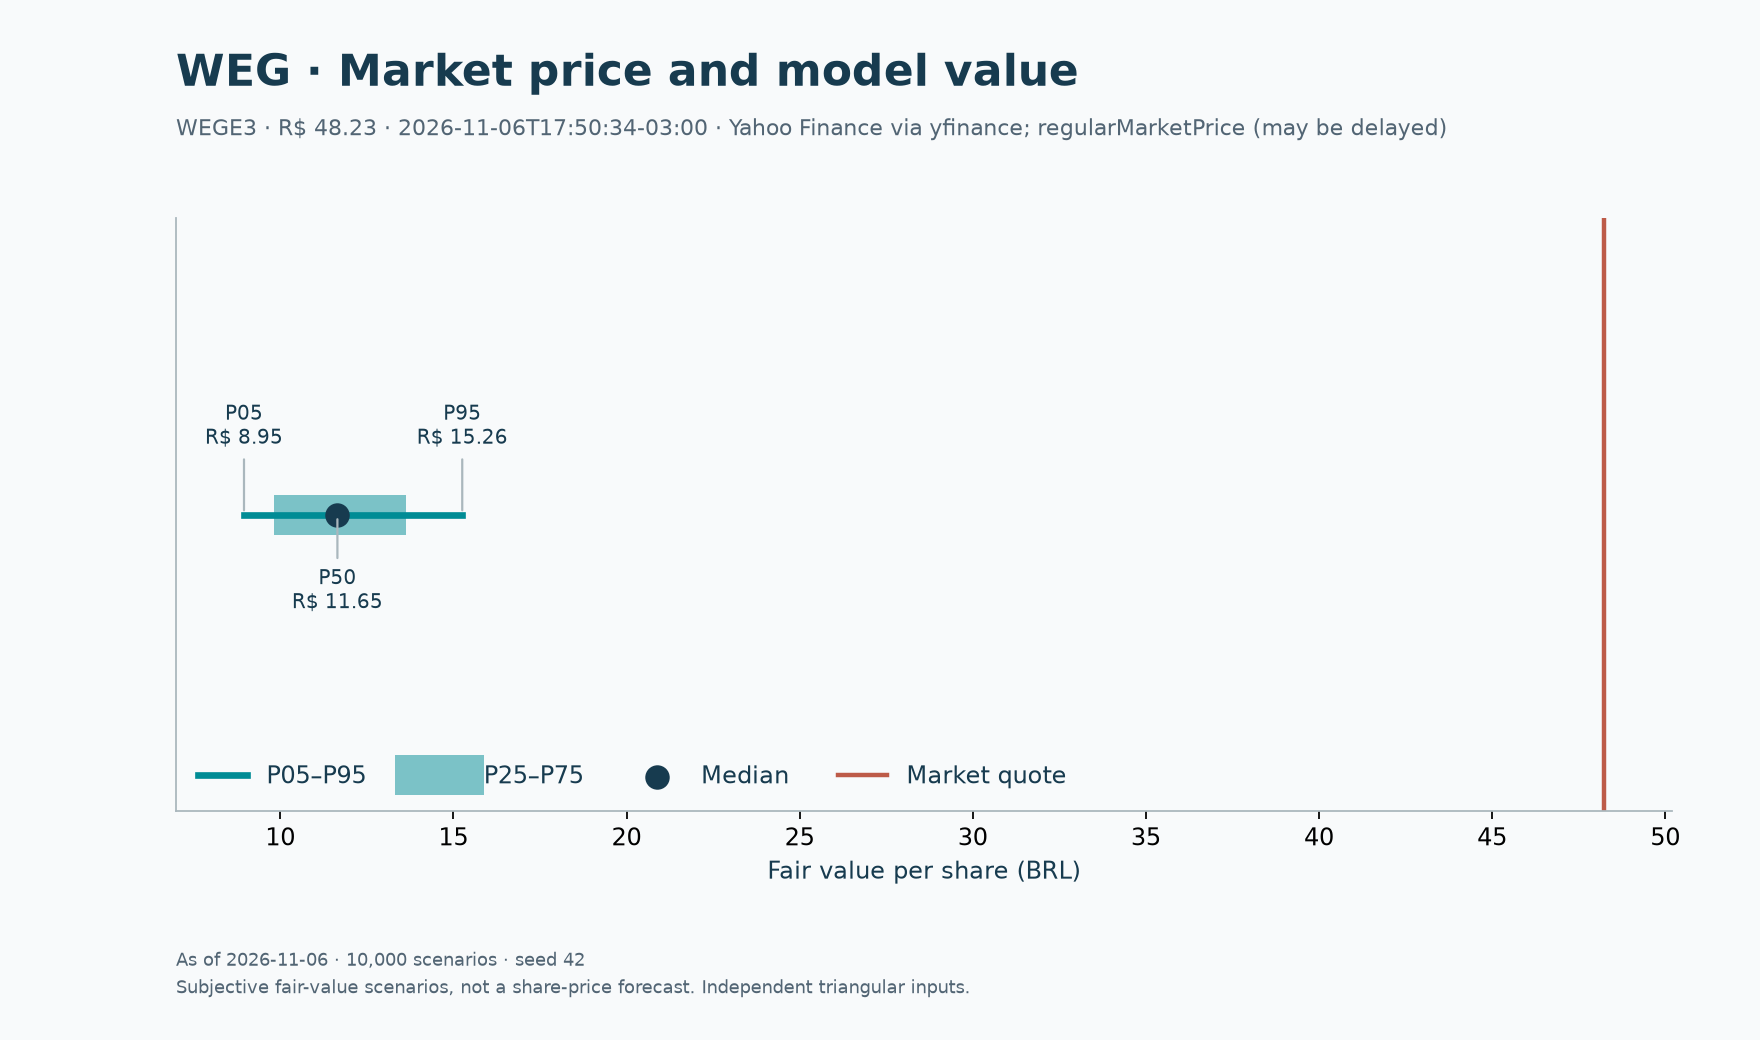

Artefatos gerados em outputs/notebook


In [6]:
paths = save_charts(simulation, output / "charts", data=data, quote=quote)
for path in paths:
    display(Image(filename=str(path), width=880))
workbook = build_workbook(output / "weg-research.xlsx", a, data=data,
                          simulation=simulation, quote=quote)
simulation.samples.to_csv(output / "monte_carlo.csv", index=False)
print("Artefatos gerados em", output.relative_to(root))

## Leitura econômica e próximos testes

Compare o crescimento assumido com a receita TTM recente, e a margem de 20% com
a margem reportada. Um preço superior ao conjunto de cenários pede hipóteses
fora desses suportes ou uma revisão estrutural do modelo. Não demonstra sozinho
que o mercado está errado. Segmentação, reinvestimento terminal, correlações entre
drivers e valor justo dos minoritários são os principais limites deste exercício.